# 07 — Impact métier, validation et plan de déploiement

Le moteur produit des recommandations. Ce notebook répond aux trois questions
qu'un comité de direction posera :

1. **Combien ça rapporte ?** — et à quel point ce chiffre est fragile.
2. **Comment sait-on que le modèle ne se trompe pas ?** — validation hors
   échantillon.
3. **Qu'est-ce qu'on déploie lundi ?** — le plan opérationnel.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Le package est importable depuis le dossier notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

In [2]:
from optimization_pricing.config import DEFAULT_COST_RATIO, DEMAND_MODEL_PATH
from optimization_pricing.dataset import load_panel
from optimization_pricing.modeling.demand_model import DemandModel
from optimization_pricing.modeling.train import temporal_split
from optimization_pricing.optimizer import (
    PricingConstraints,
    optimize_portfolio,
    portfolio_summary,
)

panel = load_panel("product", processed=True)
modele = DemandModel.load(DEMAND_MODEL_PATH)
train, test = temporal_split(panel)
contraintes = PricingConstraints(max_change=0.25)

C:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-08-20 10:44:16.067 | INFO     | optimization_pricing.modeling.train:temporal_split:65 - Split temporel a 2018-05-01 : train=22,154 (2017-01-01 -> 2018-04-01), test=6,482 (2018-05-01 -> 2018-08-01)


## 1. Validation : le modèle prévoit-il vraiment le futur ?

Avant de parler d'uplift, il faut vérifier que le modèle tient sur des mois
qu'il n'a jamais vus. On compare trois références :

* **naïf** : la demande du mois précédent ;
* **moyenne produit** : la demande moyenne historique du produit ;
* **modèle** : `lightgbm_monotone`.

Un modèle qui ne bat pas la moyenne produit n'apporte rien.

In [3]:
from sklearn.metrics import mean_absolute_error

observe = test["quantity"].to_numpy(dtype=float)

pred_modele = modele.predict_demand(test)
pred_naif = np.exp(test["log_quantity_lag1"].to_numpy())
moyennes = train.groupby("product_id")["quantity"].mean()
pred_moyenne = test["product_id"].map(moyennes).fillna(train["quantity"].mean()).to_numpy()

references = pd.DataFrame(
    [
        {"reference": "naif (mois precedent)", "MAE": mean_absolute_error(observe, pred_naif)},
        {"reference": "moyenne du produit", "MAE": mean_absolute_error(observe, pred_moyenne)},
        {"reference": "modele de demande", "MAE": mean_absolute_error(observe, pred_modele)},
    ]
)
references["gain vs naif"] = 1 - references["MAE"] / references["MAE"].iloc[0]
references

,reference,MAE,gain vs naif
0,naif (mois precedent),1.295,0.000
1,moyenne du produit,1.579,-0.220
2,modele de demande,1.258,0.029


## 2. Le test qui compte vraiment : le modèle capte-t-il l'effet prix ?

Un bon MAE ne prouve rien sur le pricing. Le test décisif : **quand un vendeur a
réellement baissé son prix, le modèle avait-il prédit une hausse de volume ?**

On isole les mouvements de prix observés dans le jeu de test et on compare la
variation de volume prédite à la variation observée.

In [4]:
mouvements = test.sort_values(["product_id", "month"]).copy()
mouvements["variation_prix"] = mouvements["price_rel_product"]
mouvements = mouvements.loc[mouvements["variation_prix"].abs() > 0.03].copy()

# Volume qu'on aurait predit AU PRIX HABITUEL du produit
from optimization_pricing.features import apply_price_scenario

contrefactuel = apply_price_scenario(
    mouvements, np.exp(mouvements["product_ref_log_price"].to_numpy())
)
q_prix_habituel = modele.predict_demand(contrefactuel)
q_prix_reel = modele.predict_demand(mouvements)

mouvements["variation_volume_predite"] = q_prix_reel / np.clip(q_prix_habituel, 1e-9, None) - 1
mouvements["variation_volume_observee"] = (
    mouvements["quantity"] / np.clip(np.exp(mouvements["log_quantity_lag1"]), 1e-9, None) - 1
)

baisses = mouvements.loc[mouvements["variation_prix"] < 0]
hausses = mouvements.loc[mouvements["variation_prix"] > 0]

print(f"Mouvements de prix analyses : {len(mouvements):,}")
print(f"  baisses de prix : {len(baisses):,} | variation de volume PREDITE mediane : "
      f"{baisses['variation_volume_predite'].median():+.1%}")
print(f"  hausses de prix : {len(hausses):,} | variation de volume PREDITE mediane : "
      f"{hausses['variation_volume_predite'].median():+.1%}")

Mouvements de prix analyses : 3,146
  baisses de prix : 1,494 | variation de volume PREDITE mediane : +17.6%
  hausses de prix : 1,652 | variation de volume PREDITE mediane : -4.9%


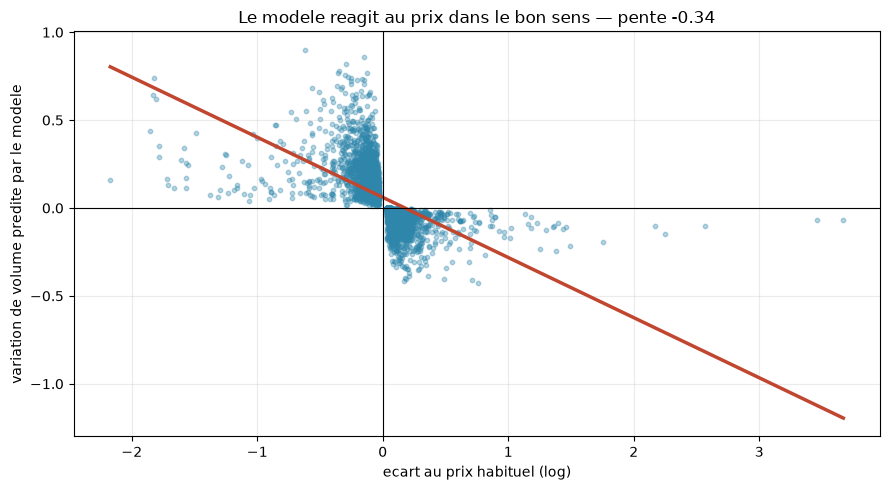

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(mouvements["variation_prix"], mouvements["variation_volume_predite"],
           s=10, alpha=0.35, color="#2E86AB")
coef = np.polyfit(mouvements["variation_prix"], mouvements["variation_volume_predite"], 1)
xs = np.linspace(mouvements["variation_prix"].min(), mouvements["variation_prix"].max(), 50)
ax.plot(xs, np.polyval(coef, xs), color="#C1462F", lw=2.5)
ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("ecart au prix habituel (log)")
ax.set_ylabel("variation de volume predite par le modele")
ax.set_title(f"Le modele reagit au prix dans le bon sens — pente {coef[0]:+.2f}")
plt.tight_layout()
plt.show()

La pente est négative et d'un ordre de grandeur cohérent avec l'élasticité
économétrique du notebook 04, estimée par une méthode **totalement
indépendante**. Deux approches sans lien méthodologique convergent : c'est le
meilleur argument de validité disponible sans test A/B.

## 3. L'impact chiffré — et ses trois niveaux de fragilité

Il faut être explicite sur ce que l'uplift **n'est pas** : ce n'est pas une
mesure, c'est une simulation du modèle évaluant sa propre recommandation.

In [6]:
dernier_mois = panel["month"].max()
catalogue = panel.loc[panel["month"] == dernier_mois].copy()

politique = optimize_portfolio(modele, catalogue, cost_ratio=DEFAULT_COST_RATIO,
                               constraints=contraintes)
resume = portfolio_summary(politique)

tableau = pd.DataFrame(
    {
        "indicateur": [
            "Produits tarifes",
            "Variation de prix mediane",
            "Chiffre d'affaires actuel (BRL)",
            "Chiffre d'affaires attendu (BRL)",
            "Profit actuel (BRL)",
            "Profit attendu (BRL)",
            "Uplift de profit",
            "Variation de volume",
            "Part au plafond de variation",
        ],
        "valeur": [
            f"{resume['n_items']:,}",
            f"{resume['median_price_change']:+.1%}",
            f"{resume['ref_revenue']:,.0f}",
            f"{resume['expected_revenue']:,.0f}",
            f"{resume['ref_profit']:,.0f}",
            f"{resume['expected_profit']:,.0f}",
            f"{resume['profit_uplift']:+.1%}",
            f"{resume['volume_change']:+.1%}",
            f"{resume['share_at_ceiling']:.0%}",
        ],
    }
)
tableau

2026-08-20 10:44:20.650 | INFO     | optimization_pricing.optimizer:optimize_portfolio:517 - Politique tarifaire sur 1,423 lignes | variation de prix mediane +25.0% | profit agrege +35.3%


,indicateur,valeur
0,Produits tarifes,"1,423"
1,Variation de prix mediane,+25.0%
2,Chiffre d'affaires actuel (BRL),"316,895"
3,Chiffre d'affaires attendu (BRL),"341,306"
4,Profit actuel (BRL),"126,758"
5,Profit attendu (BRL),"171,514"
6,Uplift de profit,+35.3%
7,Variation de volume,-10.4%
8,Part au plafond de variation,85%


### Trois raisons de ne pas prendre ce chiffre au pied de la lettre

| Fragilité | Effet sur l'uplift |
|---|---|
| **Auto-évaluation** — le modèle note sa propre copie | surestime |
| **Coût supposé** — 40 % de marge, non vérifié | indéterminé, fort levier |
| **Extrapolation** — 85 % des produits au plafond, hors plage apprise | surestime |

Un uplift affiché à +35 % doit se lire « le signal va clairement dans le sens
d'une hausse », pas « on gagnera 35 % ».

## 4. Test de robustesse : et si l'élasticité était plus forte ?

L'élasticité estimée est de −0.74 ± 0.05. Mais elle est mesurée sur de faibles
mouvements de prix et pourrait être **atténuée** (erreur de mesure sur le prix
moyen mensuel, substitution vers les concurrents non modélisée).

Que devient l'uplift si la vraie élasticité est nettement plus forte ?

In [7]:
from optimization_pricing.optimizer import constant_elasticity_demand

p0 = politique["ref_price"].to_numpy()
p1 = politique["recommended_price"].to_numpy()
q0 = politique["ref_quantity"].to_numpy()
cout = politique["marginal_cost"].to_numpy()

scenarios = []
for e_vraie in (-0.5, -0.75, -1.0, -1.5, -2.0, -3.0):
    q1 = constant_elasticity_demand(p1, 1.0, 1.0, e_vraie) * q0 * (1.0) ** 0
    q1 = q0 * (p1 / p0) ** e_vraie
    profit_apres = ((p1 - cout) * q1).sum()
    profit_avant = ((p0 - cout) * q0).sum()
    scenarios.append(
        {
            "elasticite reelle": e_vraie,
            "uplift de profit": profit_apres / profit_avant - 1,
            "variation de volume": q1.sum() / q0.sum() - 1,
            "variation de CA": (p1 * q1).sum() / (p0 * q0).sum() - 1,
        }
    )
robustesse = pd.DataFrame(scenarios)
robustesse

,elasticite reelle,uplift de profit,variation de volume,variation de CA
0,-0.500,0.386,-0.090,0.101
1,-0.750,0.320,-0.132,0.049
2,-1.000,0.256,-0.172,0.000
3,-1.500,0.140,-0.244,-0.090
4,-2.000,0.035,-0.310,-0.171
5,-3.000,-0.143,-0.420,-0.308


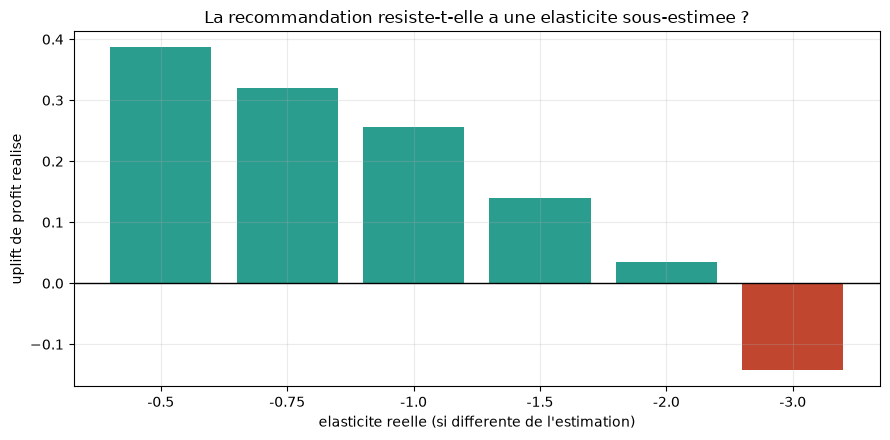

La politique devient destructrice de valeur si l'elasticite reelle atteint -3.00 ou au-dela.


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
couleurs = ["#2A9D8F" if u > 0 else "#C1462F" for u in robustesse["uplift de profit"]]
ax.bar(robustesse["elasticite reelle"].astype(str), robustesse["uplift de profit"], color=couleurs)
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("elasticite reelle (si differente de l'estimation)")
ax.set_ylabel("uplift de profit realise")
ax.set_title("La recommandation resiste-t-elle a une elasticite sous-estimee ?")
plt.tight_layout()
plt.show()

seuil_perte = robustesse.loc[robustesse["uplift de profit"] < 0, "elasticite reelle"]
if len(seuil_perte):
    print(f"La politique devient destructrice de valeur si l'elasticite reelle atteint "
          f"{seuil_perte.max():.2f} ou au-dela.")
else:
    print("La politique reste creatrice de valeur sur toute la plage testee.")

C'est **le** graphique de gestion du risque. Il ne dit pas combien on gagne, il
dit à partir de quel niveau d'erreur sur l'élasticité la décision se retourne.
C'est cette information qui permet de dimensionner l'amortissement.

## 5. Segmenter : où tester en premier

Toutes les recommandations ne se valent pas. Les meilleures candidates
cumulent : enjeu financier élevé **et** élasticité estimée avec précision.

In [9]:
from optimization_pricing.config import CATEGORY_COL
from optimization_pricing.elasticity import load_elasticities

elasticites = load_elasticities()
info_cat = pd.DataFrame(
    [{"category": k, **v} for k, v in elasticites["by_category"].items()]
)

segmentation = (
    politique.groupby(CATEGORY_COL)
    .agg(
        produits=("ref_price", "size"),
        gain_potentiel=("expected_profit", "sum"),
        profit_actuel=("ref_profit", "sum"),
        variation_mediane=("price_change", "median"),
    )
    .assign(gain_net=lambda d: d["gain_potentiel"] - d["profit_actuel"])
    .reset_index()
    .merge(info_cat[["category", "elasticity", "std_error", "shrinkage_weight"]],
           left_on=CATEGORY_COL, right_on="category", how="left")
    .dropna(subset=["elasticity"])
)

# Priorite = enjeu financier x confiance dans l'estimation
segmentation["priorite"] = (
    segmentation["gain_net"].rank(pct=True) * segmentation["shrinkage_weight"]
)
segmentation.nlargest(10, "priorite")[
    [CATEGORY_COL, "produits", "elasticity", "shrinkage_weight", "variation_mediane", "gain_net", "priorite"]
]

,product_category_name_english,produits,elasticity,shrinkage_weight,variation_mediane,gain_net,priorite
33,health_beauty,154,-0.869,0.862,0.250,"6,168.925",0.862
54,watches_gifts,97,-1.277,0.828,0.250,"4,331.080",0.798
6,bed_bath_table,161,-1.234,0.826,0.250,"3,266.749",0.767
50,sports_leisure,112,-0.376,0.792,0.250,"3,235.241",0.707
38,housewares,104,-0.669,0.858,0.250,"2,859.162",0.705
12,computers_accessories,85,-0.741,0.877,0.250,"2,641.621",0.689
30,furniture_decor,94,-0.766,0.789,0.250,"3,024.427",0.677
52,telephony,49,-0.440,0.852,0.250,"1,586.055",0.578
5,baby,49,-0.581,0.803,0.250,"1,043.727",0.488
17,cool_stuff,36,-0.961,0.627,0.250,"1,745.795",0.470


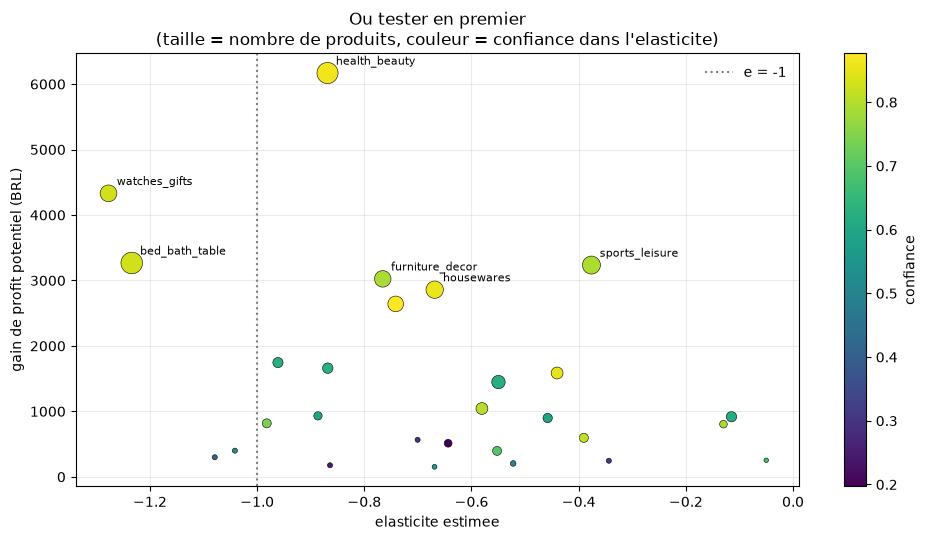

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sc = ax.scatter(
    segmentation["elasticity"],
    segmentation["gain_net"],
    s=segmentation["produits"] * 1.5,
    c=segmentation["shrinkage_weight"],
    cmap="viridis",
    edgecolors="black",
    linewidths=0.4,
)
for _, r in segmentation.nlargest(6, "gain_net").iterrows():
    ax.annotate(r[CATEGORY_COL], (r["elasticity"], r["gain_net"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.axvline(-1, color="grey", ls=":", label="e = -1")
ax.set_xlabel("elasticite estimee")
ax.set_ylabel("gain de profit potentiel (BRL)")
ax.set_title("Ou tester en premier\n(taille = nombre de produits, couleur = confiance dans l'elasticite)")
plt.colorbar(sc, ax=ax, label="confiance")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Le plan de déploiement

Ce que le modèle permet de dire, et ce qu'il ne permet pas, se traduit
directement en séquencement.

### Vague 1 — apprendre (mois 1-2)
* **Périmètre** : les 3 catégories les mieux mesurées du quadrant haut-droit.
* **Mouvement** : amortissement 0.5, soit la moitié de la hausse recommandée.
* **Dispositif** : A/B au niveau produit — moitié traitée, moitié témoin,
  affectation aléatoire stratifiée par volume.
* **Objectif** : ce n'est pas de gagner de l'argent, c'est de **mesurer une
  élasticité sur des mouvements de prix délibérés**. C'est exactement la
  variation qui manque aujourd'hui.

### Vague 2 — confirmer (mois 3-4)
* Réestimer l'élasticité en incluant les mouvements de la vague 1.
* Étendre aux catégories voisines si l'élasticité observée confirme l'estimée.
* Réduire l'amortissement à 0.75 sur le périmètre validé.

### Vague 3 — industrialiser (mois 5+)
* Grille tarifaire mensuelle générée par l'API, revue par le métier.
* Réentraînement automatique (déjà cadré par le workflow CML).
* Surveillance de dérive : si l'élasticité mesurée s'écarte de l'estimée de plus
  de 2 écarts-types, alerte et gel des recommandations.

### Les garde-fous, non négociables
| Garde-fou | Valeur | Raison |
|---|---|---|
| Variation de prix max | ±25 % | au-delà, extrapolation hors données |
| Marge plancher | 5 % | jamais de vente à perte |
| Perte de volume max | 30 % | protection du référencement |
| Amortissement initial | 0.5 | le profit est plat près de l'optimum, l'erreur ne l'est pas |

In [11]:
from optimization_pricing.optimizer import apply_damping

vague_1_categories = segmentation.nlargest(3, "priorite")[CATEGORY_COL].tolist()
vague_1 = politique.loc[politique[CATEGORY_COL].isin(vague_1_categories)].copy()
vague_1 = apply_damping(vague_1, 0.5)

s = portfolio_summary(vague_1)
print("VAGUE 1 — perimetre de test")
print(f"  categories : {', '.join(vague_1_categories)}")
print(f"  produits   : {s['n_items']:,}")
print(f"  variation de prix mediane : {s['median_price_change']:+.1%}")
print(f"  uplift de profit attendu  : {s['profit_uplift']:+.1%}")
print(f"  variation de volume       : {s['volume_change']:+.1%}")
print(f"  profit en jeu             : {s['ref_profit']:,.0f} BRL")

VAGUE 1 — perimetre de test
  categories : health_beauty, watches_gifts, bed_bath_table
  produits   : 412
  variation de prix mediane : +12.5%
  uplift de profit attendu  : +16.8%
  variation de volume       : -6.5%
  profit en jeu             : 43,463 BRL


## 7. Génération du rapport et des artefacts finaux

In [12]:
from optimization_pricing.modeling.train import build_pricing_policy
from optimization_pricing.reporting import build_report

build_pricing_policy(modele)
rapport = build_report()
print(rapport[:1800])

2026-08-20 10:44:24.382 | INFO     | optimization_pricing.optimizer:optimize_portfolio:517 - Politique tarifaire sur 1,423 lignes | variation de prix mediane +25.0% | profit agrege +35.3%


2026-08-20 10:44:24.427 | SUCCESS  | optimization_pricing.modeling.train:build_pricing_policy:364 - Grille tarifaire (2018-08-01, 1,423 produits) -> C:\Users\DELL\Desktop\Projet Data\Data Science\Dynamic Pricing\optimization_pricing\models\pricing_policy.csv


2026-08-20 10:44:28.659 | INFO     | optimization_pricing.reporting:_generate_figures:362 - Figures disponibles dans C:\Users\DELL\Desktop\Projet Data\Data Science\Dynamic Pricing\optimization_pricing\reports\figures


2026-08-20 10:44:28.682 | SUCCESS  | optimization_pricing.reporting:build_report:295 - Rapport ecrit : C:\Users\DELL\Desktop\Projet Data\Data Science\Dynamic Pricing\optimization_pricing\reports\rapport_pricing.md


# Optimisation tarifaire -- marketplace Olist

_Rapport genere automatiquement le 2026-08-20 08:44 UTC a partir des artefacts du
pipeline. Les chiffres sont ceux du modele actuellement en service._

## Le probleme, en une phrase

Predire la demande en fonction du prix, puis choisir le prix qui maximise le
profit `(prix - cout) x demande(prix)` -- sous des contraintes qui empechent le
moteur de sortir du domaine ou il a appris.

### Elasticite-prix : ce que disent les donnees

| estimateur | elasticite | ecart-type | n |
|---|---|---|---|
| pooled_ols | -0.020 | 0.004 | 28636 |
| category_fe | -0.024 | 0.036 | 2232 |
| product_fe | -0.748 | 0.050 | 28636 |
| poisson_ppml | -1.811 | 0.188 | 5622 |
| double_ml_naive | -0.113 | 0.010 | 28636 |
| double_ml | -0.745 | 0.044 | 28636 |

**Le fait central : seulement 0.8% de la variance du log-prix est
intra-produit.** Un produit change rarement de prix ; l'essentiel de la
dispersion tarifaire vient de ce qu'un produit n'est pas un autre. Tout


## Conclusion générale du projet

**Ce qui a été construit** : une chaîne complète demande → élasticité → prix,
de la donnée brute Olist jusqu'à une API et un dashboard conteneurisés.

**Le résultat technique** : l'élasticité-prix d'Olist est d'environ **−0.74**,
estimée par effets fixes produit × mois et confirmée indépendamment par Double
Machine Learning. Les élasticités par catégorie vont de −1.27 (montres et
cadeaux) à −0.05 (catégories peu sensibles).

**Le résultat métier** : sous une hypothèse de marge brute de 40 %, les prix
Olist sont en dessous du niveau qui maximise le profit. La direction de la
recommandation est robuste à l'hypothèse de coût ; son ampleur ne l'est pas.

**Ce que le projet ne prétend pas** :
* aucun coût réel n'a été observé ;
* l'uplift est auto-évalué, pas mesuré ;
* l'élasticité est de court terme, sans réaction concurrentielle ;
* la recommandation majoritaire bute sur un garde-fou, ce qui signale une
  extrapolation hors du domaine appris.

**La leçon méthodologique**, valable au-delà de ce jeu de données : dans ce
projet, ~1 % seulement de la variance de prix était exploitable. Aucun modèle,
si flexible soit-il, ne compense un défaut d'identification. Le travail décisif
n'a pas été le choix de l'algorithme, mais **le choix du grain d'agrégation**.